<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/Kopie_von_Pandas4_lesson_28_29_10_26_grouping%2C_pivot_tables.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐼📈 Pandas і графіки для аналітиків · Блокнот 4 з 7
## Групування та зведені таблиці · 📈 Графіки з групувань

Більшість запитань до аналітика звучать як **«…по кожному…»**:
- виручка **по кожному місту**;
- середній чек **по кожному каналу продажів**;
- кількість замовлень **по кожній категорії і місяцю**.

Для цього в pandas є **групування** (`groupby`) і **зведені таблиці** (`pivot_table`). Це той самий інструмент, що зведені таблиці в Excel або `GROUP BY` в SQL.

### У цьому блокноті ви навчитеся
1. Рахувати частоти: `value_counts()`.
2. Групувати: `groupby()` з однією і кількома метриками.
3. Будувати зведені таблиці: `pivot_table()` і `crosstab()`.
4. 📈 Малювати результат групування з **підписами значень**.
5. 📈 Будувати **згруповані**, **складені** та **100%-ві** стовпчики зі зведених таблиць.
6. 📈 Розфарбовувати таблицю як **теплову карту**, як умовне форматування в Excel.

### Як працювати з блокнотом
- Запускайте клітинки **по черзі зверху вниз**: кнопка ▶ ліворуч або **`Shift + Enter`**.
- **Першою** запустіть клітинку «📦 Підготовка даних»: вона створить файли з даними.
- Змінюйте числа й умови в прикладах і дивіться, що вийде. Зламати нічого не можна.
- У практиці пишіть код у клітинках «Ваш код тут». Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Спершу спробуйте самостійно, а туди зазирайте, лише якщо справді застрягли.
- Розділи з позначкою **📈** — про графіки. Вони йдуть паралельно з pandas і поступово ускладнюються від блокнота до блокнота.

<details>
<summary><b>📚 Увесь курс</b></summary>

01. Знайомство з pandas · 📈 Перший графік<br>02. Вибір, фільтрація та сортування · 📈 Налаштовуємо вигляд графіка<br>03. Нові стовпці та очищення даних · 📈 Графіки для перевірки даних<br>**04. Групування та зведені таблиці · 📈 Графіки з групувань** ← ви тут<br>05. Об'єднання таблиць · 📈 Порівняння і зв'язки<br>06. Робота з датами · 📈 Графіки динаміки<br>07. Фінальний проєкт · 📈 Дашборд для керівника

</details>

## Крок 0. Готуємо дані

In [1]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює навчальні файли з даними інтернет-магазину за 2025 рік.
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---------- Товари ----------
products = pd.DataFrame([
    ("P01", "Headphones",         "Electronics", 1500,  900),
    ("P02", "Power bank",         "Electronics",  900,  520),
    ("P03", "Smartwatch",    "Electronics", 4200, 2900),
    ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
    ("P05", "T-shirt",          "Clothing",         450,  180),
    ("P06", "Hoodie",              "Clothing",        1200,  550),
    ("P07", "Jeans",            "Clothing",        1600,  800),
    ("P08", "Sneakers",          "Clothing",        2800, 1600),
    ("P09", "Mug",             "Home",          180,   60),
    ("P10", "Blanket",              "Home",          850,  400),
    ("P11", "Desk lamp",   "Home",         1100,  600),
    ("P12", "Towel set",    "Home",          650,  300),
    ("P13", "Face cream",  "Beauty",        520,  210),
    ("P14", "Shampoo",           "Beauty",        260,  110),
    ("P15", "Perfume",           "Beauty",       2400, 1300),
    ("P16", "Yoga mat",  "Sports",        700,  320),
    ("P17", "Water bottle",   "Sports",        350,  140),
    ("P18", "Dumbbells 5 kg",      "Sports",        950,  550),
], columns=["product_id", "product", "category", "price", "cost"])

# ---------- Клієнти ----------
n_cust = 400
names = ["Olena", "Andrii", "Mariia", "Ihor", "Nataliia", "Dmytro", "Iryna", "Oleksandr",
         "Tetiana", "Serhii", "Yuliia", "Maksym", "Oksana", "Viktor", "Anna", "Bohdan",
         "Kateryna", "Taras", "Sofiia", "Roman"]
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 3 * 365, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
    "name": rng.choice(names, n_cust),
    "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
    "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
    "registration_date": reg.strftime("%Y-%m-%d"),
})

# ---------- Замовлення ----------
n = 3000
days = pd.date_range("2025-01-01", "2025-12-31")
w = np.linspace(0.85, 1.15, len(days))          # магазин поступово росте
w[days.month.isin([6, 7, 8])] *= 0.8            # влітку спокійніше
w[days.month.isin([11, 12])] *= 1.5             # сезон розпродажів і свят
w[days.dayofweek >= 5] *= 1.3                   # у вихідні купують більше
w[days == pd.Timestamp("2025-11-28")] *= 6      # Чорна п'ятниця
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

cust_w = rng.gamma(1.0, 1, n_cust)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
prod_w = 1 / np.sqrt(products["price"].to_numpy())
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
payment = rng.choice(["Card", "Cash on delivery", "Google/Apple Pay"], n, p=[0.55, 0.27, 0.18])
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

cod = payment == "Cash on delivery"
u = rng.random(n)
status = np.where(u < np.where(cod, 0.80, 0.91), "Delivered",
                  np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"))

city = customers["city"].to_numpy()[cust_idx]
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

rating = np.where(deliv_days >= 4,
                  rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
                  rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1).astype(float)
returned = status == "Returned"
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

orders = pd.DataFrame({
    "order_id": np.arange(100001, 100001 + n),
    "order_date": order_date.strftime("%Y-%m-%d"),
    "delivery_date": delivery_str,
    "customer_id": customers["customer_id"].to_numpy()[cust_idx],
    "product_id": products["product_id"].to_numpy()[prod_idx],
    "quantity": quantity,
    "payment": payment,
    "channel": channel,
    "status": status,
    "rating": rating,
})

# ---------- Одна велика таблиця продажів ----------
sales = (orders.merge(customers[["customer_id", "city"]], on="customer_id", how="left")
               .merge(products[["product_id", "product", "category", "price"]], on="product_id", how="left"))
sales = sales[["order_id", "order_date", "delivery_date", "customer_id", "city", "category",
               "product", "price", "quantity", "payment", "channel", "status", "rating"]]
sales = sales.sort_values("order_id").reset_index(drop=True)

# ---------- Квартальні вивантаження ----------
quarter = pd.to_datetime(sales["order_date"]).dt.quarter
for q in range(1, 5):
    sales[quarter == q].to_csv(f"sales_2025_Q{q}.csv", index=False)

# ---------- «Брудне» вивантаження продажів ----------
raw = sales.copy()
raw["price"] = raw["price"].astype(str) + " UAH"
raw["order_date"] = pd.to_datetime(raw["order_date"]).dt.strftime("%d.%m.%Y")
raw["delivery_date"] = pd.to_datetime(raw["delivery_date"]).dt.strftime("%d.%m.%Y")
messy = {"Kyiv": ["kyiv", "KYIV", " Kyiv", "Kiev"], "Lviv": ["lviv", "Lviv ", " LVIV"],
         "Odesa": ["odesa", "Odesa "], "Kharkiv": ["kharkiv", "KHARKIV "], "Dnipro": ["dnipro", " Dnipro"]}
city_col = raw["city"].to_numpy(dtype=object)
for i in rng.choice(n, 300, replace=False):
    city_col[i] = rng.choice(messy[city_col[i]])
city_col[rng.choice(n, 15, replace=False)] = None
raw["city"] = city_col
qty_col = raw["quantity"].to_numpy(dtype=float)
qty_col[rng.choice(n, 40, replace=False)] = np.nan
raw["quantity"] = qty_col
pay_col = raw["payment"].to_numpy(dtype=object)
pay_col[rng.choice(n, 60, replace=False)] = None
raw["payment"] = pay_col
raw = pd.concat([raw, raw.iloc[rng.choice(n, 25, replace=False)]])
raw = raw.sort_values("order_id", kind="stable").reset_index(drop=True)
raw.columns = ["Order ID", "Order Date", "Delivery Date", "Customer ID", "City", "Category",
               "Product", "Price", "Qty", "Payment", "Channel", "Status", "Rating"]

# ---------- «Брудний» список клієнтів ----------
craw = customers.copy()
name_col = craw["name"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 40, replace=False):
    name_col[i] = rng.choice([name_col[i].lower(), name_col[i].upper(), " " + name_col[i] + " "])
craw["name"] = name_col
cc = craw["city"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 50, replace=False):
    cc[i] = rng.choice([cc[i].lower(), cc[i].upper(), cc[i] + " "])
craw["city"] = cc
age_col = craw["age"].to_numpy(dtype=float)
age_col[rng.choice(n_cust, 12, replace=False)] = np.nan
craw["age"] = age_col
craw["registration_date"] = pd.to_datetime(craw["registration_date"]).dt.strftime("%d/%m/%Y")
craw = pd.concat([craw, craw.iloc[rng.choice(n_cust, 8, replace=False)]])
craw = craw.sort_values("customer_id", kind="stable").reset_index(drop=True)

# ---------- Зберігаємо файли ----------
sales.to_csv("sales.csv", index=False)
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)
raw.to_csv("sales_raw.csv", index=False)
craw.to_csv("customers_raw.csv", index=False)

# ---------- Налаштування вигляду таблиць і стиль графіків (з блокнота 2) ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

del (rng, names, cities, reg, n, n_cust, days, w, order_date, cust_w, cust_idx, prod_w, prod_idx,
     quantity, payment, channel, cod, u, status, city, deliv_days, delivery, delivery_str, rating,
     returned, quarter, q, raw, messy, city_col, qty_col, pay_col, craw, name_col, cc, age_col, i,
     sales, orders, customers, products)

print("✅ Done! Data files created:")
print("   sales.csv, orders.csv, customers.csv, products.csv,")
print("   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv")

✅ Done! Data files created:
   sales.csv, orders.csv, customers.csv, products.csv,
   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sales.csv")
df["revenue"] = df["price"] * df["quantity"]      # сума замовлення (як у блокноті 3)

df.head(3)

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating,revenue
0,100001,2025-01-01,NaN,C0230,Kyiv,Sports,Dumbbells 5 kg,950,4,Card,Website,Cancelled,NaN,3800
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00,12600
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN,4200


💡 **Про виручку.** Скасовані й повернені замовлення грошей магазину не принесли. Поки ми вчимося, рахуємо всі замовлення, а в практиці та фінальному проєкті порахуємо «справжню» виручку лише з доставлених.

---
## Крок 1. Підрахунок: `value_counts()`

Найпростіше групування: «скільки разів трапляється кожне значення».

In [3]:
df["channel"].value_counts()

,count
channel,
Website,1513
App,1039
Instagram,448


Щоб отримати **частки** замість кількості, додайте `normalize=True`. Помноживши на 100, отримаємо відсотки:

In [4]:
(df["channel"].value_counts(normalize=True) * 100).round(1)

,proportion
channel,
Website,50.40
App,34.60
Instagram,14.90


---
## Крок 2. Групування: `groupby()`

### 2.1 Як це працює
`groupby` виконує три кроки:

| 1. Розбити таблицю на групи | 2. Порахувати щось у кожній групі | 3. Зібрати результати разом |
|---|---|---|
| Kyiv: 900, 1500 | Kyiv: 900 + 1500 = **2400** | Kyiv — 2400 |
| Lviv: 450, 2800 | Lviv: 450 + 2800 = **3250** | Lviv — 3250 |

У коді це читається майже як речення:

**`df.groupby("за чим групуємо")["що рахуємо"].як_рахуємо()`**

In [5]:
df.groupby("city")["revenue"].sum()

,revenue
city,
Dnipro,563640
Kharkiv,632330
Kyiv,1283120
Lviv,885590
Odesa,621940


«Згрупуй за містом, візьми виручку, порахуй суму.»

Результат відсортований за алфавітом. Щоб побачити лідерів, відсортуємо за значенням:

In [6]:
city_revenue = df.groupby("city")["revenue"].sum().sort_values(ascending=False)
city_revenue

,revenue
city,
Kyiv,1283120
Lviv,885590
Kharkiv,632330
Odesa,621940
Dnipro,563640


### 2.2 Різні способи порахувати

| Метод | Що рахує | Приклад питання |
|---|---|---|
| `.sum()` | суму | виручка по містах |
| `.mean()` | середнє | середній чек по каналах |
| `.median()` | медіану | «типовий» чек |
| `.count()` | кількість заповнених значень | скільки замовлень |
| `.nunique()` | кількість **унікальних** значень | скільки різних клієнтів |
| `.min()` / `.max()` | мінімум / максимум | найдешевший товар у категорії |

In [7]:
print("Average order value by channel:")
print(df.groupby("channel")["revenue"].mean().round(2))

print("\nUnique customers by category:")
print(df.groupby("category")["customer_id"].nunique())

Average order value by channel:
channel
App         1 319.87
Instagram   1 492.86
Website     1 286.50
Name: revenue, dtype: float64

Unique customers by category:
category
Beauty         230
Clothing       232
Electronics    229
Home           275
Sports         231
Name: customer_id, dtype: int64


### 2.3 Групування за кількома стовпцями
Передайте **список** стовпців. Результат матиме «двоповерховий» індекс:

In [8]:
s = df.groupby(["city", "channel"])["revenue"].sum()
s

city     channel  
Dnipro   App          206180
         Instagram     88600
         Website      268860
Kharkiv  App          227610
         Instagram    117790
         Website      286930
Kyiv     App          396770
         Instagram    212380
         Website      673970
Lviv     App          299600
         Instagram    173700
         Website      412290
Odesa    App          241180
         Instagram     76330
         Website      304430
Name: revenue, dtype: int64

Це **Series**: один стовпець даних (`revenue`) і двоповерховий індекс із міста й каналу. Тому підписи стоять на різних рівнях: зверху назва даних `revenue`, а рядком нижче назви рівнів індексу `city` і `channel`. Однакові міста pandas не повторює, щоб таблицю було легше читати.

Звернутися до значень можна через `.loc`, вказуючи значення індексу. Одне значення: обидва рівні в круглих дужках, як пара:

In [9]:
s.loc[("Kyiv", "App")]

np.int64(396770)

Усі канали одного міста: досить вказати лише **зовнішній** рівень:

In [10]:
s.loc["Kyiv"]

,revenue
channel,
App,396770
Instagram,212380
Website,673970


За **внутрішнім** рівнем через `.loc` так просто не вибрати: `s.loc["App"]` дасть помилку, бо pandas шукатиме місто з назвою `App`. Для цього є `.xs()` (від *cross-section*, «зріз»). У `level` вказуємо, на якому рівні шукати:

In [11]:
s.xs("App", level="channel")

,revenue
city,
Dnipro,206180
Kharkiv,227610
Kyiv,396770
Lviv,299600
Odesa,241180


Працювати з таким результатом можна, але читати й зберігати його незручно. **`reset_index()`** перетворює його на звичайну плоску таблицю, де місто і канал стають стовпцями:

In [12]:
city_channel = df.groupby(["city", "channel"])["revenue"].sum().reset_index()
city_channel.head(6)

,city,channel,revenue
0,Dnipro,App,206180
1,Dnipro,Instagram,88600
2,Dnipro,Website,268860
3,Kharkiv,App,227610
4,Kharkiv,Instagram,117790
5,Kharkiv,Website,286930


---
## Крок 3. Кілька метрик одразу: `agg()`

Часто для кожної групи потрібно кілька показників: кількість замовлень, виручка, середній чек, кількість клієнтів. Для цього є `agg()`. Записується так:

**`нова_назва=("стовпець", "як_рахувати")`**

In [13]:
city_stats = df.groupby("city").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    avg_check=("revenue", "mean"),
    customers=("customer_id", "nunique"),
)

city_stats

,orders,revenue,avg_check,customers
city,,,,
Dnipro,442,563640,1 275.20,54
Kharkiv,493,632330,1 282.62,52
Kyiv,957,1283120,1 340.77,124
Lviv,678,885590,1 306.18,76
Odesa,430,621940,1 446.37,51


Це вже готовий звіт! З результатом можна працювати як зі звичайною таблицею: додавати стовпці, сортувати, фільтрувати.

Додамо **частку кожного міста** у загальній виручці:

In [14]:
city_stats["revenue_share_%"] = (city_stats["revenue"] / city_stats["revenue"].sum() * 100).round(1)

city_stats.sort_values("revenue", ascending=False)

,orders,revenue,avg_check,customers,revenue_share_%
city,,,,,
Kyiv,957,1283120,1 340.77,124,32.20
Lviv,678,885590,1 306.18,76,22.20
Kharkiv,493,632330,1 282.62,52,15.90
Odesa,430,621940,1 446.37,51,15.60
Dnipro,442,563640,1 275.20,54,14.10


---
## 📈 Крок 4. Графік з групування

Коли після `groupby` ми вибираємо **один** стовпець, як-от `df.groupby("city")["revenue"].sum()`, результат — це Series. Тож малюється він так само, як у блокнотах 1–2: горизонтальні стовпчики, найбільший зверху, підписи значень замість осі.

💡 Якщо вибрати кілька стовпців (`[["revenue", "quantity"]]`) або порахувати кілька метрик через `.agg()`, результат буде вже таблицею (DataFrame), як у кроці 3.

Великі суми зручніше показувати в **тисячах гривень**: ділимо на 1000 і округлюємо.

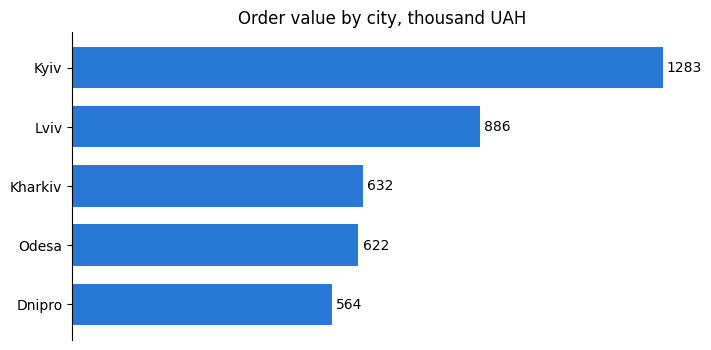

In [15]:
city_revenue_k = (df.groupby("city")["revenue"].sum() / 1000).round().sort_values()

ax = city_revenue_k.plot(kind="barh", width=0.7)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)     # fmt="%.0f" — без знаків після коми
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
plt.title("Order value by city, thousand UAH")
plt.ylabel("")
plt.show()

💡 Одиниці виміру («thousand UAH») винесено в заголовок: тоді підписи на стовпчиках короткі й не дублюють «UAH» п'ять разів.

---
## Крок 5. Зведена таблиця: `pivot_table()`

Те саме, що зведена таблиця в Excel: обираєте, що буде в **рядках**, що в **стовпцях** і що **рахувати** в клітинках.

| Параметр | Що задає | Аналог в Excel |
|---|---|---|
| `index` | рядки | «Рядки» |
| `columns` | стовпці | «Стовпці» |
| `values` | що рахуємо | «Значення» |
| `aggfunc` | як рахуємо: `"sum"`, `"mean"`, `"count"` | «Підсумовувати за…» |

In [17]:
pivot = pd.pivot_table(
    df,
    index="city",
    columns="category",
    values="revenue",
    aggfunc="sum",
)

pivot

category,Beauty,Clothing,Electronics,Home,Sports
city,,,,,
Dnipro,99900,142000,165000,83590,73150
Kharkiv,118100,141600,199800,111130,61700
Kyiv,156400,316950,426600,219970,163200
Lviv,148280,204250,267000,163310,102750
Odesa,86600,142400,227100,92590,73250


### 📈 Згруповані стовпчики: графік зі зведеної таблиці
Зведена таблиця малюється одразу: **рядки стають групами** на осі, а **стовпці — кольоровими стовпчиками** всередині групи. Що означає кожен колір, пояснює **легенда**.

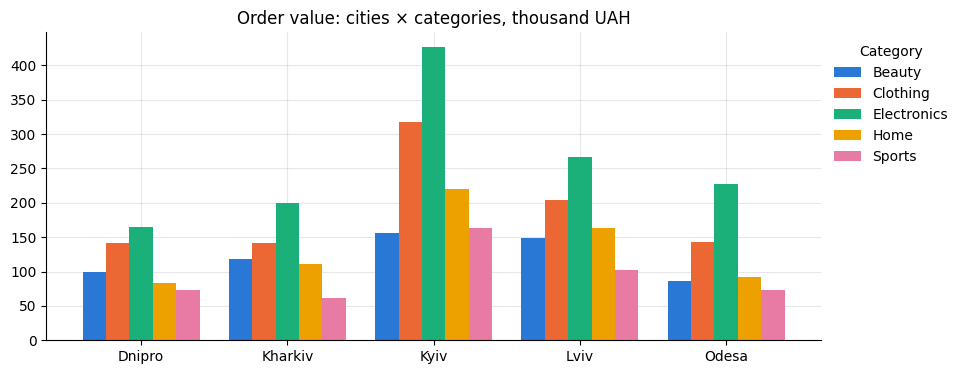

In [18]:
(pivot / 1000).plot(kind="bar", rot=0, figsize=(10, 4), width=0.8)
plt.title("Order value: cities × categories, thousand UAH")
plt.xlabel("")
plt.legend(title="Category", bbox_to_anchor=(1, 1), loc="upper left")   # легенда праворуч від графіка
plt.show()

💡 `bbox_to_anchor=(1, 1), loc="upper left"` виносить легенду **за межі** графіка, праворуч угорі, щоб вона не закривала стовпчики.

Згруповані стовпчики добре порівнюють категорії **всередині** одного міста. Але коли кольорів більше 4–5, графік стає строкатим, і його краще розбити на кілька.

### 📈 Складені стовпчики: `stacked=True`
Якщо важливіше **загальне** значення по місту і **з чого воно складається**, поставте сегменти один на одного. Міста відсортуємо за загальною сумою:

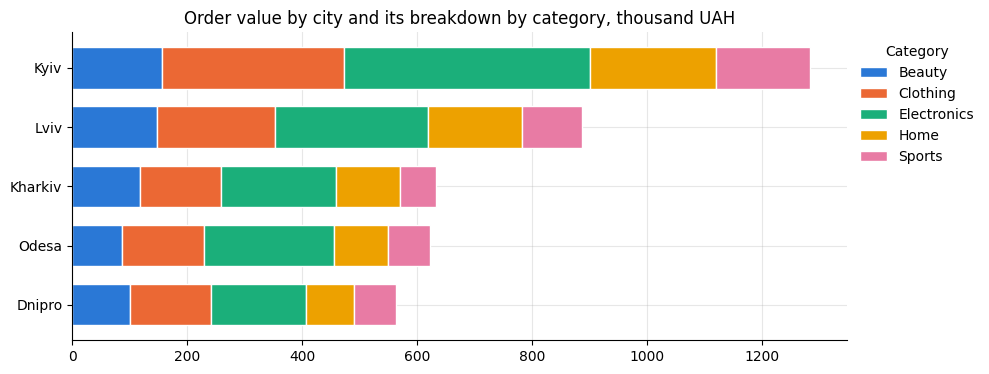

In [19]:
order = pivot.sum(axis=1).sort_values().index          # міста від меншої загальної суми до більшої

(pivot.loc[order] / 1000).plot(kind="barh", stacked=True, figsize=(10, 4), width=0.7,
                               edgecolor="white", linewidth=1)    # тонкі білі межі між сегментами
plt.title("Order value by city and its breakdown by category, thousand UAH")
plt.ylabel("")
plt.legend(title="Category", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

💡 Довжину першого сегмента (того, що починається від нуля) легко порівнювати між містами, а от середніх — важко: кожен з них починається в іншому місці. Тому найважливішу категорію ставлять першою.

Сегменти йдуть у тому самому порядку, що й стовпці зведеної таблиці, а `pivot_table` ставить стовпці за алфавітом. Щоб змінити порядок, виберіть стовпці в потрібній послідовності перед побудовою графіка. Наприклад, щоб першою була категорія `Home`: `pivot = pivot[["Home", "Beauty", "Clothing", "Electronics", "Sports"]]`..

Корисні доповнення:
- `margins=True` додає рядок і стовпець **`"Total"`** (`margins_name` задає їхню назву);
- `fill_value=0` ставить 0 замість порожніх клітинок (якщо в якійсь комбінації не було продажів).

In [21]:
pd.pivot_table(
    df,
    index="city",
    columns="channel",
    values="order_id",
    aggfunc="count",
    margins=True,
    margins_name="Total",
    fill_value=0,
)

channel,App,Instagram,Website,Total
city,,,,
Dnipro,161,55,226,442
Kharkiv,160,87,246,493
Kyiv,325,150,482,957
Lviv,229,110,339,678
Odesa,164,46,220,430
Total,1039,448,1513,3000


### 📈 Теплова карта прямо в таблиці
Іноді таблиця краща за графік, бо потрібні точні числа. Але й таблицю можна зробити наочною, розфарбувавши клітинки за значенням, як **умовне форматування в Excel**:

In [22]:
(pivot / 1000).style.background_gradient(cmap="Blues").format("{:.0f}")

category,Beauty,Clothing,Electronics,Home,Sports
city,,,,,
Dnipro,100,142,165,84,73
Kharkiv,118,142,200,111,62
Kyiv,156,317,427,220,163
Lviv,148,204,267,163,103
Odesa,87,142,227,93,73


Чим темніша клітинка, тим більше значення. Одразу видно, що найбільша комбінація — `Electronics` у Києві.

- `.style` вмикає оформлення таблиці;
- `background_gradient(cmap="Blues")` — заливка від світлого до темного (`cmap` — набір кольорів: `"Blues"`, `"Greens"`, `"Oranges"`);
- `.format("{:.0f}")` — показати числа без знаків після коми.

⚠️ `.style` — лише для показу. Результат — вже не таблиця для розрахунків, тож не зберігайте його в змінну, з якою працюватимете далі.

---
## Крок 6. Таблиця «хто з ким»: `crosstab()`

`pd.crosstab(рядки, стовпці)` рахує, скільки разів трапляється кожна **комбінація** двох значень. А з `normalize="index"` вона показує **частки в кожному рядку** (кожен рядок у сумі дає 1).

Перевіримо гіпотезу: чи впливає спосіб оплати на те, чи скасують замовлення?

In [23]:
(pd.crosstab(df["payment"], df["status"], normalize="index") * 100).round(1)

status,Cancelled,Delivered,Returned
payment,,,
Card,5.60,91.20,3.20
Cash on delivery,11.40,81.10,7.50
Google/Apple Pay,4.10,92.60,3.30


### 📈 100%-ві стовпчики: частки на одному графіку
Таблицю часток зручно показати стовпчиками, де кожен стовпчик — це 100%. Кольори підбираємо **зі змістом**: проблеми — червоний і помаранчевий, доставлені — нейтральний сірий. І ставимо проблеми **першими**, від нуля, щоб їхню довжину було легко порівняти.

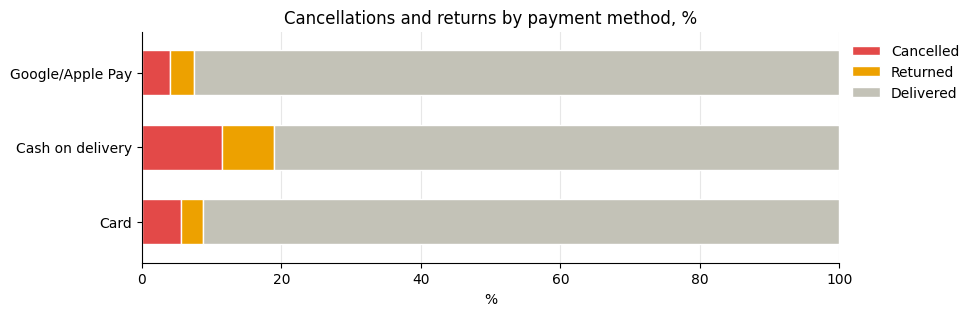

In [25]:
status_share = pd.crosstab(df["payment"], df["status"], normalize="index") * 100
status_share = status_share[["Cancelled", "Returned", "Delivered"]]      # порядок сегментів зліва направо

status_share.plot(
    kind="barh", stacked=True, figsize=(9, 3), width=0.6, edgecolor="white", linewidth=1,
    color=["#e34948", "#eda100", "#c3c2b7"],                               # по кольору на кожен стовпець таблиці
)
plt.title("Cancellations and returns by payment method, %")
plt.xlabel("%")
plt.ylabel("")
plt.xlim(0, 100)
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

**💡 Інсайт:** замовлення з **накладеним платежем** скасовують і повертають помітно частіше. Клієнт нічого не заплатив наперед, тож йому легше відмовитися. Це вже питання до бізнесу: може, варто запропонувати знижку за онлайн-оплату?

Саме так групування перетворюється на **висновки**.

---
# ✍️ Практика

**Завдання 1.** Скільки замовлень надійшло з кожного каналу продажів (`channel`)? А яка частка кожного каналу у відсотках?

In [27]:
print(df["channel"].value_counts())
print()
print((df["channel"].value_counts(normalize=True) * 100).round(1))

channel
Website      1513
App          1039
Instagram     448
Name: count, dtype: int64

channel
Website     50.40
App         34.60
Instagram   14.90
Name: proportion, dtype: float64


**Завдання 2.** Порахуйте суму замовлень (`revenue`) по категоріях, від більшої до меншої. Побудуйте горизонтальний стовпчиковий графік.

<Axes: ylabel='category'>

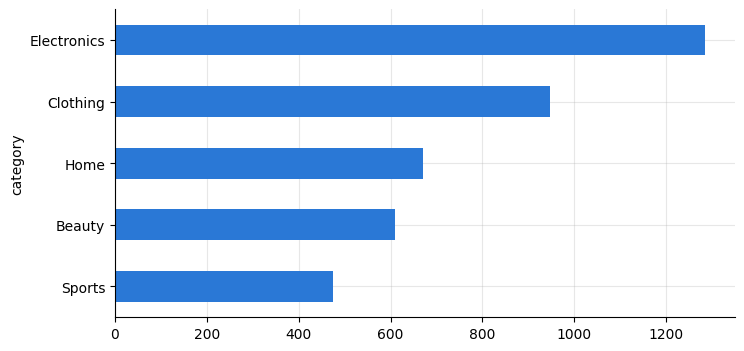

In [28]:
category_revenue = df.groupby("category")["revenue"].sum().sort_values()

(category_revenue / 1000).plot(kind="barh")

**Завдання 3.** Яка середня оцінка (`rating`) кожного товару? Покажіть 5 товарів з **найнижчою** середньою оцінкою.

In [29]:
product_rating = df.groupby("product")["rating"].mean().round(2)
display(product_rating.sort_values().head(5))


,rating
product,
Bluetooth speaker,3.71
Power bank,3.74
Hoodie,3.75
Blanket,3.80
Jeans,3.84


**Завдання 4.** Зробіть звіт по каналах продажів: кількість замовлень, сума замовлень, середній чек, кількість унікальних клієнтів. Відсортуйте за сумою замовлень.

In [31]:
channel_stats = df.groupby("channel").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    avg_check=("revenue", "mean"),
    customers=("customer_id", "nunique"),
)
display(channel_stats.sort_values("revenue", ascending=False))

,orders,revenue,avg_check,customers
channel,,,,
Website,1513,1946480,1 286.50,322
App,1039,1371340,1 319.87,286
Instagram,448,668800,1 492.86,213


**Завдання 5.** Побудуйте зведену таблицю: рядки — категорії, стовпці — способи оплати, у клітинках — **середній чек**. Округліть до цілих.

In [32]:
pivot = pd.pivot_table(
    df,
    index="category",
    columns="payment",
    values="revenue",
    aggfunc="mean",
).round(0)
display(pivot)

payment,Card,Cash on delivery,Google/Apple Pay
category,,,
Beauty,1 020.00,1 092.00,982.00
Clothing,1 680.00,1 711.00,1 806.00
Electronics,2 664.00,2 542.00,3 346.00
Home,814.00,701.00,815.00
Sports,892.00,829.00,942.00


**Завдання 6 ⭐.** Порахуйте **справжню виручку**, тобто лише з **доставлених** замовлень (`status == "Delivered"`), по містах. Додайте частку кожного міста у відсотках.

In [34]:
delivered = df[df["status"] == "Delivered"]

city_real = delivered.groupby("city")["revenue"].sum().sort_values(ascending=False).to_frame()
city_real["share_%"] = (city_real["revenue"] / city_real["revenue"].sum() * 100).round(1)
display(city_real)

,revenue,share_%
city,,
Kyiv,1132350,32.10
Lviv,787490,22.30
Kharkiv,563960,16.00
Odesa,560270,15.90
Dnipro,480750,13.60


**Завдання 7 📈.** Побудуйте зведену таблицю **кількості замовлень**: рядки — міста, стовпці — канали продажів. Намалюйте її як згруповані стовпчики з легендою праворуч.

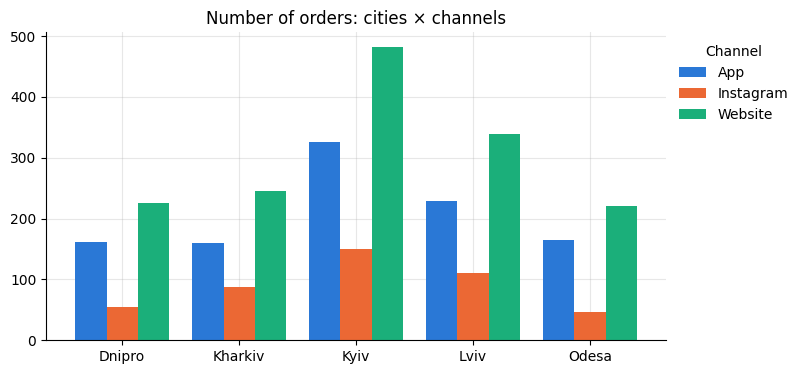

In [36]:
city_channel = pd.pivot_table(df, index="city", columns="channel", values="order_id", aggfunc="count")

city_channel.plot(kind="bar", rot=0, width=0.8)
plt.title("Number of orders: cities × channels")
plt.xlabel("")
plt.legend(title="Channel", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

**Завдання 8 📈.** Розфарбуйте таблицю середнього чека з завдання 5 (категорії × способи оплати) як теплову карту з кольоровою гамою `"Greens"`.

In [37]:
avg_check = pd.pivot_table(df, index="category", columns="payment", values="revenue", aggfunc="mean")
display(avg_check.style.background_gradient(cmap="Greens").format("{:.0f}"))

payment,Card,Cash on delivery,Google/Apple Pay
category,,,
Beauty,1020,1092,982
Clothing,1680,1711,1806
Electronics,2664,2542,3346
Home,814,701,815
Sports,892,829,942


**Завдання 9 📈⭐.** Яку **частку** замовлень у кожному місті дає кожен канал продажів? Побудуйте 100%-ві горизонтальні стовпчики.

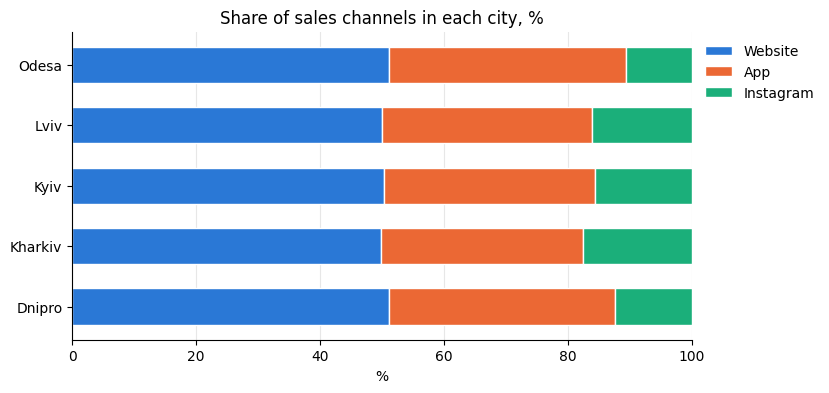

In [39]:
channel_share = pd.crosstab(df["city"], df["channel"], normalize="index") * 100
channel_share = channel_share[["Website", "App", "Instagram"]]

channel_share.plot(kind="barh", stacked=True, width=0.6, edgecolor="white", linewidth=1)
plt.title("Share of sales channels in each city, %")
plt.xlabel("%")
plt.ylabel("")
plt.xlim(0, 100)
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

---
# 📋 Шпаргалка блокнота 4

| Код | Що робить |
|---|---|
| `df["col"].value_counts()` | скільки разів трапляється кожне значення |
| `df["col"].value_counts(normalize=True)` | те саме, але частки |
| `df.groupby("a")["b"].sum()` | сума `b` для кожного `a` |
| `.mean()`, `.median()`, `.count()`, `.nunique()`, `.min()`, `.max()` | інші способи порахувати |
| `df.groupby(["a", "b"])["c"].sum().reset_index()` | групування за двома стовпцями → плоска таблиця |
| `s.loc[("Kyiv", "App")]`, `s.loc["Kyiv"]`, `s.xs("App", level="channel")` | вибрати значення з двоповерхового індексу |
| `df.groupby("a").agg(name=("col", "sum"), ...)` | кілька метрик одразу |
| `pd.pivot_table(df, index=..., columns=..., values=..., aggfunc=...)` | зведена таблиця |
| `margins=True`, `fill_value=0` | рядок і стовпець «Total», нулі замість порожніх клітинок |
| `pd.crosstab(df["a"], df["b"], normalize="index")` | частки комбінацій |
| `series.plot(kind="barh")` | горизонтальний стовпчиковий графік |
| `.to_frame()` | перетворити Series на таблицю |

**📈 Графіки**

| Код | Що робить |
|---|---|
| `ax.bar_label(ax.containers[0], fmt="%.0f")` | підписи значень без знаків після коми |
| `pivot.plot(kind="bar")` | згруповані стовпчики (рядки → групи, стовпці → кольори) |
| `pivot.plot(kind="barh", stacked=True, edgecolor="white")` | складені стовпчики з білими межами між сегментами |
| `crosstab(..., normalize="index") * 100` → `plot(kind="barh", stacked=True)` | 100%-ві стовпчики |
| `color=["#e34948", "#eda100", ...]` | свій колір для кожного ряду даних |
| `plt.legend(title="...", bbox_to_anchor=(1, 1), loc="upper left")` | легенда з заголовком, праворуч від графіка |
| `table.style.background_gradient(cmap="Blues").format("{:.0f}")` | теплова карта в таблиці |
| `pivot.loc[order]` | змінити порядок рядків перед графіком |

---
### ➡️ Далі: блокнот 5 «Об'єднання таблиць»
Як з'єднати замовлення, клієнтів і товари в одну таблицю: аналог ВПР (VLOOKUP) в Excel. А 📈 у графіках: порівняння двох показників і точкова діаграма для пошуку зв'язків.

In [ ]:
# @title 💡 Розв'язки практики: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ---------- Завдання 1 ----------
print(df["channel"].value_counts())
print()
print((df["channel"].value_counts(normalize=True) * 100).round(1))

# ---------- Завдання 2 ----------
cat_revenue = df.groupby("category")["revenue"].sum().sort_values()

(cat_revenue / 1000).plot(kind="barh")
plt.title("Order value by category, thousand UAH")
plt.xlabel("thousand UAH")
plt.ylabel("")
plt.show()

display(cat_revenue.sort_values(ascending=False))

# ---------- Завдання 3 ----------
product_rating = df.groupby("product")["rating"].mean().round(2)
display(product_rating.sort_values().head(5))

# ---------- Завдання 4 ----------
channel_stats = df.groupby("channel").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    avg_check=("revenue", "mean"),
    customers=("customer_id", "nunique"),
)
display(channel_stats.sort_values("revenue", ascending=False))

# ---------- Завдання 5 ----------
avg_check = pd.pivot_table(
    df,
    index="category",
    columns="payment",
    values="revenue",
    aggfunc="mean",
).round(0)
display(avg_check)

# ---------- Завдання 6 ⭐ ----------
delivered = df[df["status"] == "Delivered"]

city_real = delivered.groupby("city")["revenue"].sum().sort_values(ascending=False).to_frame()
city_real["share_%"] = (city_real["revenue"] / city_real["revenue"].sum() * 100).round(1)
display(city_real)

# ---------- Завдання 7 📈 ----------
city_channel = pd.pivot_table(df, index="city", columns="channel", values="order_id", aggfunc="count")

city_channel.plot(kind="bar", rot=0, width=0.8)
plt.title("Number of orders: cities × channels")
plt.xlabel("")
plt.legend(title="Channel", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

# ---------- Завдання 8 📈 ----------
avg_check = pd.pivot_table(df, index="category", columns="payment", values="revenue", aggfunc="mean")
display(avg_check.style.background_gradient(cmap="Greens").format("{:.0f}"))

# ---------- Завдання 9 📈⭐ ----------
channel_share = pd.crosstab(df["city"], df["channel"], normalize="index") * 100
channel_share = channel_share[["Website", "App", "Instagram"]]

channel_share.plot(kind="barh", stacked=True, width=0.6, edgecolor="white", linewidth=1)
plt.title("Share of sales channels in each city, %")
plt.xlabel("%")
plt.ylabel("")
plt.xlim(0, 100)
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.show()
